# Weekly project
This weeks weekly project is a continuation of last weeks exercises.

You are to make a handwritten number classifier. Where we will be using the [mnist dataset](https://en.wikipedia.org/wiki/MNIST_database).

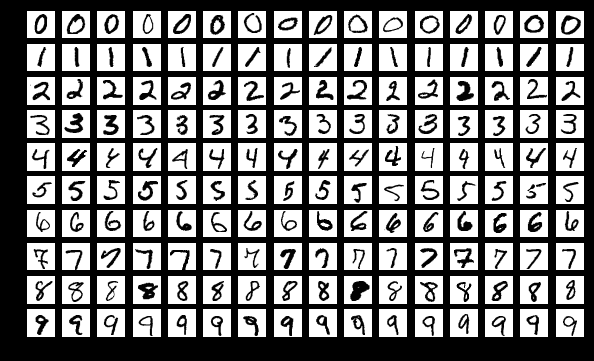

**Create a program that given an image from the mnist dataset.**
- You are free to use any algorithm you want to achieve this.
- It should be able to given a number classify what number it is.
- Accuracy should at least be 80%

If you decide to use a svm make sure you also use dimensionality reduction. SVM of the full mnist dataset will take around 4-8 hours depending on your pc.



**Challange:**
- Try to reach 98% accuracy.
- Try to classify faces with the labeled wild faces dataset [lwf](http://vis-www.cs.umass.edu/lfw/)
```{Python}
from sklearn.datasets import fetch_lfw_people
lfw_people = fetch_lfw_people(min_faces_per_person=70, resize=0.4)
```

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import time
import datetime as dt
from sklearn.decomposition import PCA
from sklearn import datasets, svm, metrics
from sklearn.datasets import fetch_openml

import ssl
ssl._create_default_https_context = ssl._create_unverified_context
mnist = fetch_openml('mnist_784', version=1)

images = mnist.data.to_numpy()
targets = mnist.target.to_numpy()

print(images.shape)
print(targets.shape)

(70000, 784)
(70000,)


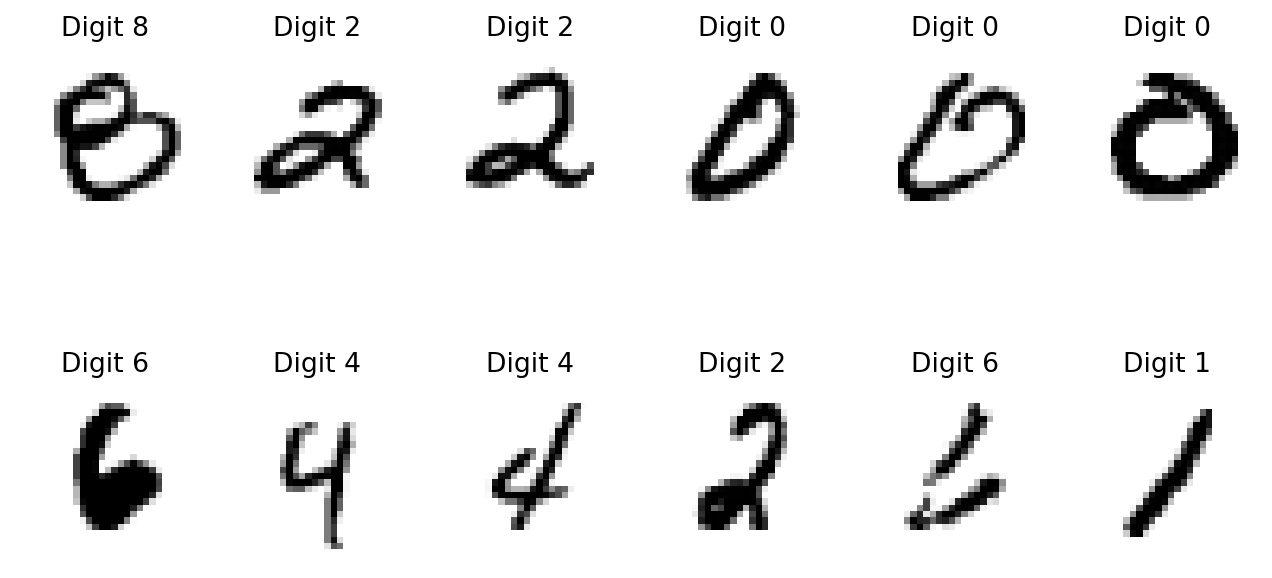

In [2]:
def show_some_digits(images, targets, sample_size=24, title_text='Digit {}' ):
    '''
    Visualize random digits in a grid plot
    images - array of flatten gidigs [:,784]
    targets - final labels
    '''
    nsamples=sample_size
    rand_idx = np.random.choice(images.shape[0], nsamples)
    images_and_labels = list(zip(images[rand_idx], targets[rand_idx]))


    img = plt.figure(1, figsize=(10, 5), dpi=160)
    for index, (image, label) in enumerate(images_and_labels):
        plt.subplot(math.ceil(nsamples/6.0), 6, index + 1)
        plt.axis('off')
        #each image is flat, we have to reshape to 2D array 28x28-784
        plt.imshow(image.reshape(28,28), cmap=plt.cm.gray_r, interpolation='nearest')
        plt.title(title_text.format(label))
    plt.show()

# draw 12 images along with their labels
show_some_digits(images, targets, 12)

## 1. Preparing the data
MNIST has 70000 images of 28x28 pixels, flattened to 784 values. We use a split where the first 60000 images are for training and the last 10000 for testing.

Every pixel is a grey value between 0 and 255, so all features already have the same range. We just divide by 255 to get values between 0 and 1. We also tried StandardScaler, but it gave a lower accuracy (around 97.6%). It blows up the border pixels, which are almost always 0, so mostly noise gets amplified.

In [3]:
X = images / 255.0
y = targets

X_train, X_test = X[:60000], X[60000:]
y_train, y_test = y[:60000], y[60000:]

print('train:', X_train.shape, 'test:', X_test.shape)
print('samples per digit in train:', np.unique(y_train, return_counts=True)[1])

train: (60000, 784) test: (10000, 784)
samples per digit in train: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


## 2. Dimensionality reduction with PCA
An SVM on all 784 pixels takes hours, so we first reduce the dimension with PCA. PCA is fitted only on the training set, then the same transform is applied to the test set.

To choose the number of components we look at the cumulative explained variance.

20 components keep 64.4% of the variance
50 components keep 82.5% of the variance
100 components keep 91.5% of the variance
150 components keep 94.8% of the variance


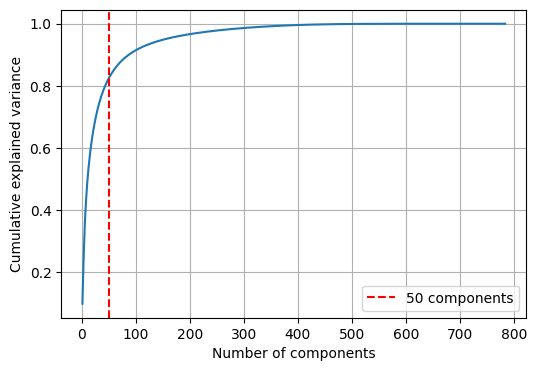

In [4]:
pca_full = PCA().fit(X_train)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

for n in [20, 50, 100, 150]:
    print(f'{n} components keep {cum_var[n-1]*100:.1f}% of the variance')

plt.figure(figsize=(6, 4))
plt.plot(np.arange(1, 785), cum_var)
plt.axvline(50, color='r', linestyle='--', label='50 components')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.grid(True)
plt.legend()
plt.show()

We pick 50 components. They keep about 82% of the variance, which looks low, but the rest is mostly small details of the handwriting that do not help to tell digits apart. To check this we reconstruct some digits from only 50 components, they are blurry but still easy to read.

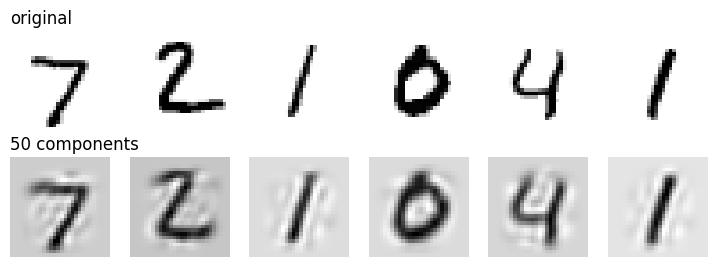

In [5]:
n_components = 50
pca = PCA(n_components=n_components)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# go back from 50 numbers to 784 pixels to see what is kept
X_rec = pca.inverse_transform(X_test_pca[:6])

fig, axes = plt.subplots(2, 6, figsize=(9, 3))
for i in range(6):
    axes[0, i].imshow(X_test[i].reshape(28, 28), cmap='gray_r')
    axes[1, i].imshow(X_rec[i].reshape(28, 28), cmap='gray_r')
    axes[0, i].axis('off')
    axes[1, i].axis('off')
axes[0, 0].set_title('original', loc='left')
axes[1, 0].set_title('50 components', loc='left')
plt.show()

## 3. Choosing C and gamma with GridSearchCV
We use an SVM with the rbf kernel. C controls how much we punish training errors and gamma how local the decision boundary is. To find good values we run GridSearchCV with 3-fold cross validation.

Running the grid search on all 60000 images would take long, so we run it on the first 10000 training images. The test set is not used here.

In [6]:
from sklearn.model_selection import GridSearchCV

param_grid = {'C': [1, 5, 10],
              'gamma': [0.01, 0.02, 0.05, 0.1]}

start = time.time()
grid = GridSearchCV(svm.SVC(kernel='rbf'), param_grid, cv=3, n_jobs=-1)
grid.fit(X_train_pca[:10000], y_train[:10000])
print(f'grid search took {time.time() - start:.0f} s')

print('best parameters:', grid.best_params_)
print(f'best cross validation accuracy: {grid.best_score_:.4f}')

grid search took 17 s
best parameters: {'C': 5, 'gamma': 0.05}
best cross validation accuracy: 0.9696


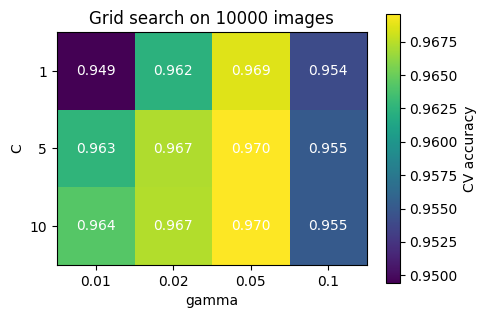

In [7]:
# cross validation accuracy for every combination
scores = grid.cv_results_['mean_test_score'].reshape(len(param_grid['C']), len(param_grid['gamma']))

plt.figure(figsize=(5, 3.5))
plt.imshow(scores, cmap='viridis')
plt.colorbar(label='CV accuracy')
plt.xticks(range(len(param_grid['gamma'])), param_grid['gamma'])
plt.yticks(range(len(param_grid['C'])), param_grid['C'])
plt.xlabel('gamma')
plt.ylabel('C')
for i in range(scores.shape[0]):
    for j in range(scores.shape[1]):
        plt.text(j, i, f'{scores[i, j]:.3f}', ha='center', va='center', color='w')
plt.title('Grid search on 10000 images')
plt.show()

## 4. Training on the full training set
Now we train the SVM with the best parameters on all 60000 training images and test it on the 10000 test images.

In [8]:
clf = svm.SVC(kernel='rbf', **grid.best_params_)

start = time.time()
clf.fit(X_train_pca, y_train)
print(f'training took {time.time() - start:.0f} s')

start = time.time()
y_pred = clf.predict(X_test_pca)
print(f'prediction took {time.time() - start:.0f} s')

print(f'train accuracy: {clf.score(X_train_pca, y_train):.4f}')
print(f'test accuracy: {metrics.accuracy_score(y_test, y_pred):.4f}')

training took 31 s
prediction took 13 s
train accuracy: 0.9999
test accuracy: 0.9868


              precision    recall  f1-score   support

           0      0.987     0.995     0.991       980
           1      0.990     0.996     0.993      1135
           2      0.983     0.985     0.984      1032
           3      0.987     0.985     0.986      1010
           4      0.990     0.986     0.988       982
           5      0.987     0.985     0.986       892
           6      0.993     0.987     0.990       958
           7      0.985     0.981     0.983      1028
           8      0.988     0.988     0.988       974
           9      0.979     0.978     0.979      1009

    accuracy                          0.987     10000
   macro avg      0.987     0.987     0.987     10000
weighted avg      0.987     0.987     0.987     10000



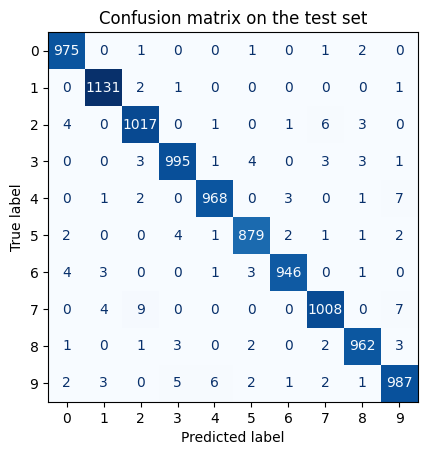

In [9]:
print(metrics.classification_report(y_test, y_pred, digits=3))

metrics.ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues', colorbar=False)
plt.title('Confusion matrix on the test set')
plt.show()

Some of the test images that the model got wrong:

number of wrong predictions: 132


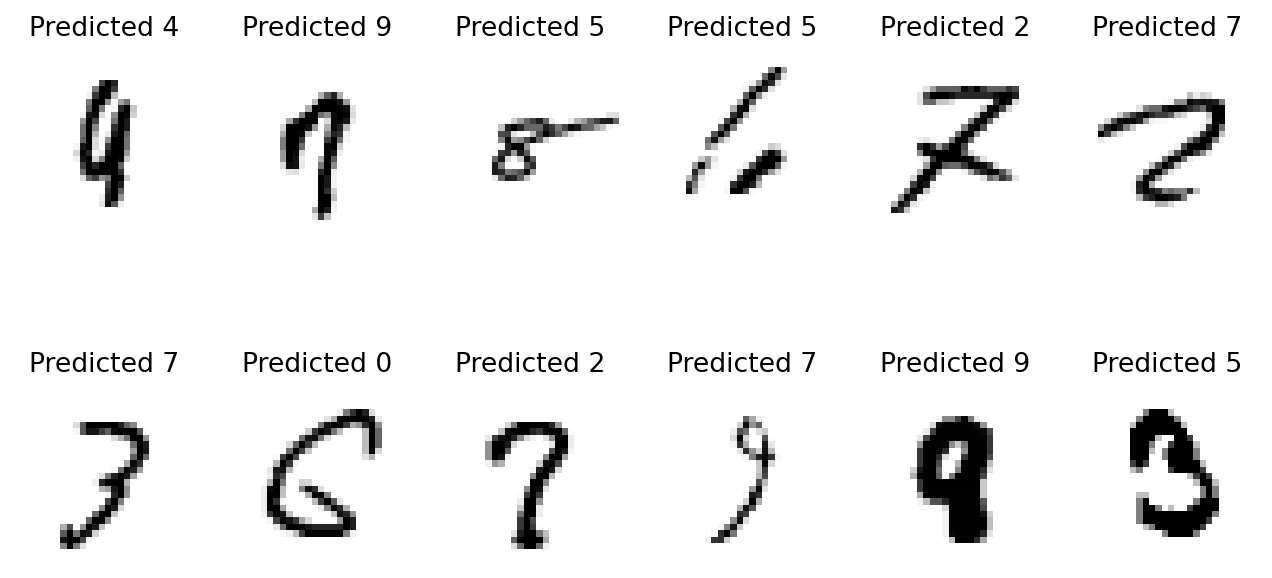

In [10]:
wrong = np.where(y_pred != y_test)[0]
print('number of wrong predictions:', len(wrong))

show_some_digits(X_test[wrong], y_pred[wrong], 12, title_text='Predicted {}')

## 5. How many components do we need?
To check our choice of 50 components, we train the same SVM with a different number of components and compare test accuracy and training time.

In [11]:
for n in [10, 20, 35, 50, 100]:
    pca_n = PCA(n_components=n)
    tr = pca_n.fit_transform(X_train)
    te = pca_n.transform(X_test)

    start = time.time()
    clf_n = svm.SVC(kernel='rbf', **grid.best_params_).fit(tr, y_train)
    print(f'{n:3d} components: test accuracy {clf_n.score(te, y_test):.4f}, training {time.time() - start:.0f} s')

 10 components: test accuracy 0.9439, training 16 s
 20 components: test accuracy 0.9810, training 18 s
 35 components: test accuracy 0.9857, training 28 s
 50 components: test accuracy 0.9868, training 46 s
100 components: test accuracy 0.9859, training 77 s


## 6. Challenge, classifying faces (LFW)
We use the same pipeline on the Labeled Faces in the Wild dataset. We keep only people with at least 70 images, which gives 7 people. The images are 50x37 pixels.

This dataset is a lot harder. There are only 1288 images, and the classes are unbalanced, George W Bush alone has 530 images. Because of that we split with stratify, so every person appears in both sets in the same proportion, and we use class_weight='balanced' in the SVM, so the small classes count more.

In [12]:
from sklearn.datasets import fetch_lfw_people
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

lfw_people = fetch_lfw_people(min_faces_per_person=70, resize=0.4)

X_f = lfw_people.data
y_f = lfw_people.target
names = lfw_people.target_names
h, w = lfw_people.images.shape[1:]

print('images:', X_f.shape, 'size:', (h, w))
for i, name in enumerate(names):
    print(f'{name}: {np.sum(y_f == i)}')

images: (1288, 1850) size: (50, 37)
Ariel Sharon: 77
Colin Powell: 236
Donald Rumsfeld: 121
George W Bush: 530
Gerhard Schroeder: 109
Hugo Chavez: 71
Tony Blair: 144


Here the pixels come from photos with different lighting, so we standardise them with StandardScaler. The scaler and PCA are fitted on the training set only.

We use 150 components with whiten=True, which scales every component to unit variance. The components are called eigenfaces and we can plot them as images.

150 components keep 94.5% of the variance


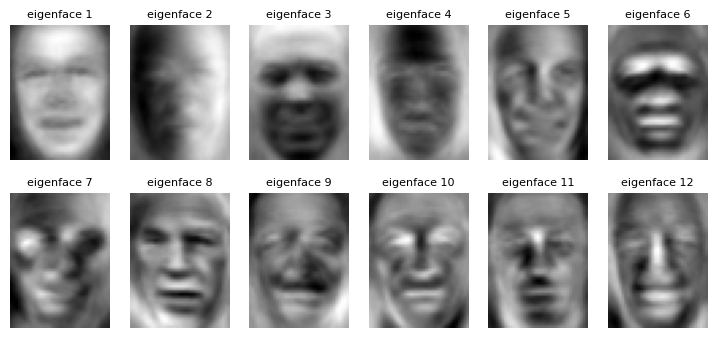

In [13]:
Xf_train, Xf_test, yf_train, yf_test = train_test_split(
    X_f, y_f, test_size=0.25, random_state=42, stratify=y_f)

scaler = StandardScaler().fit(Xf_train)
Xf_train = scaler.transform(Xf_train)
Xf_test = scaler.transform(Xf_test)

pca_f = PCA(n_components=150, whiten=True, random_state=42)
Xf_train_pca = pca_f.fit_transform(Xf_train)
Xf_test_pca = pca_f.transform(Xf_test)
print(f'150 components keep {pca_f.explained_variance_ratio_.sum()*100:.1f}% of the variance')

fig, axes = plt.subplots(2, 6, figsize=(9, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(pca_f.components_[i].reshape(h, w), cmap='gray')
    ax.set_title(f'eigenface {i+1}', fontsize=8)
    ax.axis('off')
plt.show()

In [14]:
param_grid_f = {'C': np.logspace(-1, 3, 9),
                'gamma': np.logspace(-4, -1, 7)}

grid_f = GridSearchCV(svm.SVC(kernel='rbf', class_weight='balanced'), param_grid_f, cv=5, n_jobs=-1)
grid_f.fit(Xf_train_pca, yf_train)
print('best parameters:', grid_f.best_params_)
print(f'best cross validation accuracy: {grid_f.best_score_:.4f}')

yf_pred = grid_f.predict(Xf_test_pca)
print(f'test accuracy: {metrics.accuracy_score(yf_test, yf_pred):.4f}')
print(metrics.classification_report(yf_test, yf_pred, target_names=names, digits=3))

best parameters: {'C': np.float64(1.0), 'gamma': np.float64(0.0031622776601683794)}
best cross validation accuracy: 0.8302
test accuracy: 0.8634
                   precision    recall  f1-score   support

     Ariel Sharon      0.889     0.842     0.865        19
     Colin Powell      0.789     0.949     0.862        59
  Donald Rumsfeld      0.846     0.733     0.786        30
    George W Bush      0.897     0.917     0.907       133
Gerhard Schroeder      0.778     0.778     0.778        27
      Hugo Chavez      0.833     0.556     0.667        18
       Tony Blair      0.969     0.861     0.912        36

         accuracy                          0.863       322
        macro avg      0.857     0.805     0.825       322
     weighted avg      0.866     0.863     0.861       322



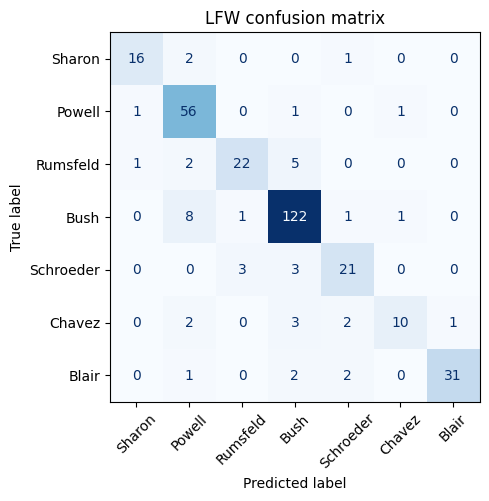

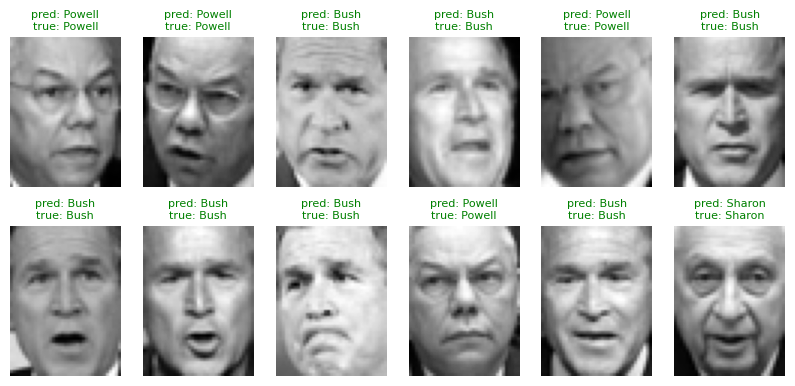

In [15]:
metrics.ConfusionMatrixDisplay.from_predictions(yf_test, yf_pred, display_labels=[n.split()[-1] for n in names],
                                                cmap='Blues', colorbar=False, xticks_rotation=45)
plt.title('LFW confusion matrix')
plt.show()

# some test faces with predicted and true name
Xf_test_img = scaler.inverse_transform(Xf_test)
fig, axes = plt.subplots(2, 6, figsize=(10, 4.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(Xf_test_img[i].reshape(h, w), cmap='gray')
    pred = names[yf_pred[i]].split()[-1]
    true = names[yf_test[i]].split()[-1]
    ax.set_title(f'pred: {pred}\ntrue: {true}', fontsize=8, color='g' if pred == true else 'r')
    ax.axis('off')
plt.show()

## Final comments
MNIST: we used PCA to go from 784 pixels to 50 components and then an SVM with rbf kernel. C and gamma were chosen with GridSearchCV on a part of the training set. On the 10000 test images we got about 98.7% accuracy. Training takes around 30 seconds, the accuracy is almost 100%, so the model fits the training data very closely, but the test accuracy is still high, so it does not overfit badly. Most mistakes are between digits that look alike, like 2 and 7, 4 and 9 or 3 and 5, and some of the wrong images are hard to read even for a person.

The component test shows that 35 to 50 components are enough. With 10 components the accuracy drops to about 94%, and with 100 it does not improve but training takes about twice as long.

LFW: the same pipeline gives around 86% accuracy. It is much lower than on MNIST, because faces change with lighting, pose and expression, and there is little data. Guessing George W Bush every time would already give about 41%, so 86% means the model learned something useful. The test set is small (322 faces), so this number can change a few percent with another split. Hugo Chavez, one of the smallest classes, has the lowest recall (about 56%). Getting much higher would need a better feature extractor, for example a CNN, which is beyond this week.

Note: We used generative AI to help with the code and comments.